# Linear Support Vector Machine:

In [118]:
load(url("https://raw.githubusercontent.com/georgios-stats/Machine_Learning_and_Neural_Networks_III_Epiphany_2024/main/misc/mockCBE2/train.data.4.Rda"))
cols <- ncol(train.data.4)
z_matrix <- train.data.4
n_obs <- nrow(z_matrix)
z_matrix[, -cols] <- as.matrix(scale(train.data.4[, -cols]))
y_numeric <- as.numeric(z_matrix[, cols])
z_matrix[,cols] <- ifelse(y_numeric == 1, -1, 1)

head(z_matrix)
n_obs

,x1,x2,y
,<dbl>,<dbl>,<dbl>
758,1.0519760,1.3633706,1
243,1.1566070,-0.7086489,-1
818,0.2184535,1.2340787,1
345,-0.3340719,0.8962045,1
619,-0.3578914,-1.5173074,-1
897,-2.1649978,-1.6781317,-1


[1] 500

SVM has class labels $ y_i \in \{-1, 1\} $
Linear SVM involves learning a hyperplane separating the two classes, specified by $$\langle w, x \rangle + b =0$$.
This hyperplane splits the space into 2 half-spaces, forming the hypothesis space $$h_{w,b} (x) = sign(\langle w, x \rangle + b) \in \{-1,1\}.$$

Then $$y_ih_{w,b}(x_i)>0$$ if the point is correctly classified. 
The margin is the min distance between a training point and the hyperplane. We want to maximise this margin so the hyperplane is robust to small peturbations in the training data. The distance between any point and the hyperplane is $$\frac{y_i ({w}^T {x}_i + b)}{||{w}||}$$

To address scale invariance and uniquely identify the hyperplane we set the score for closest points (support vectors) to the hyperplane is equal to 1. $$\text{min}_i \left(y_i ({w}^T {x}_i + b)\right) = 1$$ Then the width of the margin is $\frac{2}{||w||}$. 

We could us the 0-1 loss function but the gradient is 0 almost everywhere, so not effective for gradient based optimisation. 
As a convex surrogate we can use the hinge loss function, $\max(0, 1 - y_i h_{w,b}(x_i))$. Whereas the 0-1 loss function only counts whether the point is on the correct side of the decision boundary, the hinge loss also considers the distance of the point from the margin.

Maximising the margin widith and the hinge loss results in the objective function:
The total objective function is 
$$J(w) = \frac{\lambda}{2} ||w||^2+ \frac{1}{n} \sum_{i=1}^{n} \max(0, 1 - y_i h_{w,b}(x_i)) $$ 


1. L2 Regularization ($||w||^2$): Maximize the margin width. 
2. Hinge Loss: Penalises misclassification. If a point is correctly classified and safely outside the margin ($y_i h_{w,b}(x_i) \ge 1$), the loss drops to 0.

$\lambda$ can be adjusted empirically to control tradeoff between the two. 

In [119]:
prediction_svm <- function(x, w, b) {
  return (as.numeric((as.matrix(x) %*% w + b)))
}

objective_svm <- function(w, b, z, lambda = 0.01) {
  x <- z[, -ncol(z), drop=FALSE]
  y <- z[, ncol(z)]
  h <- prediction_svm(x, w, b)
  
  hinge <- pmax(0, 1 - y * h)
  L2_penalty <- (lambda / 2) * sum(w^2)
  loss <- L2_penalty + mean(hinge)
  
  return(loss)
}

For a single observation $(x_i, y_i)$, the gradients for the parameter update step are:

* $1 - y_i h_w(x_i) > 0:$
The point is misclassified or inside the margin. The model must adjust the line.
$$ g_{b} = -y_i $$
$$ g_{w} = \lambda w - y_i x_i $$

* $1 - y_i h_w(x_i) \le 0:$
The point is correctly classified and outside the margin. The hinge loss is 0. 
$$ g_{b} = 0 $$
$$ g_{w} = \lambda w $$

The width of the margin is $\frac{2}{||w||}$. By adjusting $\lambda$, we can prioritise the strictness of the boundary. 
* Low $\lambda$ - penalise misclassifications more strongly. Results in a tight margin.
* High $\lambda$ - prioritise L2 penalty (shrink weights), more robust generalised boundary but with a looser margin. 

In [120]:
subgradient <- function(w, b, z, lambda = 0.01) {
  x <- z[, -ncol(z), drop=FALSE]
  y <- z[, ncol(z)]
  n <- nrow(z)

  scores <- 1 - y * prediction_svm(x, w, b)

  is_misclassified <- scores > 0

  grad_b <- mean(-y * is_misclassified)
  grad_w <- lambda * w + colMeans(x * (-y * is_misclassified))
  
  return(list(grad_w=grad_w, grad_b=grad_b))
}

In [146]:
adagrad_svm <- function(z, m = 64, eta = 0.5, lambda= 0.01, Tmax = 1000, eps = 1e-6) {
  w <- rep(0.0, times=ncol(z)-1)
  b <- 0.0 

  w_chain <-matrix(NA, nrow = Tmax, ncol = length(w))
  b_chain <- rep(NA, times=Tmax)
  loss_chain <- rep(NA, times = Tmax)
  G_w <- rep(0.0, times = length(w))
  G_b <- 0.0

  for (t in 1:Tmax) {
    J <- sample.int(n = n_obs, size = m, replace = TRUE)
    z_batch <- z[J, , drop = FALSE]
    subgrads <- subgradient(w, b, z_batch, lambda)
    G_w <- G_w + subgrads$grad_w**2
    G_b <- G_b + subgrads$grad_b**2
    w <- w - eta * (1 / sqrt(G_w + eps)) * subgrads$grad_w
    b <- b - eta * (1 / sqrt(G_b + eps)) * subgrads$grad_b

    w_chain[t, ] <- w
    b_chain[t] <- b
    loss_chain[t] <- objective_svm(w, b, z, lambda)
  }
  return(list(w_chain=w_chain, b_chain=b_chain, loss_chain=loss_chain))
}

In [147]:
model_results <- adagrad_svm(z_matrix, lambda = 0.002)
w_chain <- model_results$w_chain
b_chain <- model_results$b_chain
loss_chain <- model_results$loss_chain

w_opt <- w_chain[nrow(w_chain), ]
b_opt <- b_chain[length(b_chain)]
final_loss <- loss_chain[length(loss_chain)]

cat("Optimal w1:", w_opt[1], "\n")
cat("Optimal w2:", w_opt[2], "\n")
cat("Optimal b :", b_opt, "\n")
cat("Corresponding loss:", final_loss)



Optimal w1: -1.420977 
Optimal w2: 3.583528 
Optimal b : 0.08997528 
Corresponding loss: 0.08038037

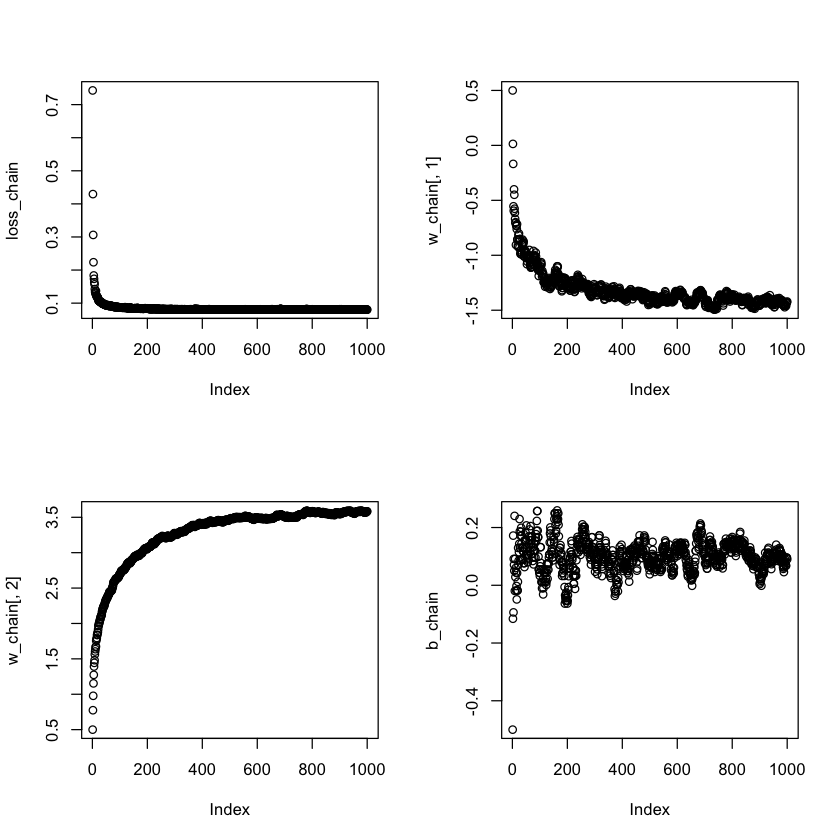

In [148]:
par(mfrow=c(2,2))
plot(loss_chain)
plot(w_chain[,1])
plot(w_chain[,2])
plot(b_chain)

To find the equation of the boundary:
$$ w^\top x + b = 0  \\ w_1x_1 + w_2x_2 + b = 0 \\ x_2 = -\frac{w_1}{w_2}x_1 + -\frac{b}{w_2}

In [149]:
library(e1071)
svm_benchmark <- svm(y ~ ., data = train.data.4, kernel = "linear", scale = TRUE, cost = 2)
w_bench <- t(svm_benchmark$coefs) %*% svm_benchmark$SV
b_bench <- -svm_benchmark$rho
slope_bench <- -w_bench[1] / w_bench[2]
intercept_bench <- -b_bench / w_bench[2]

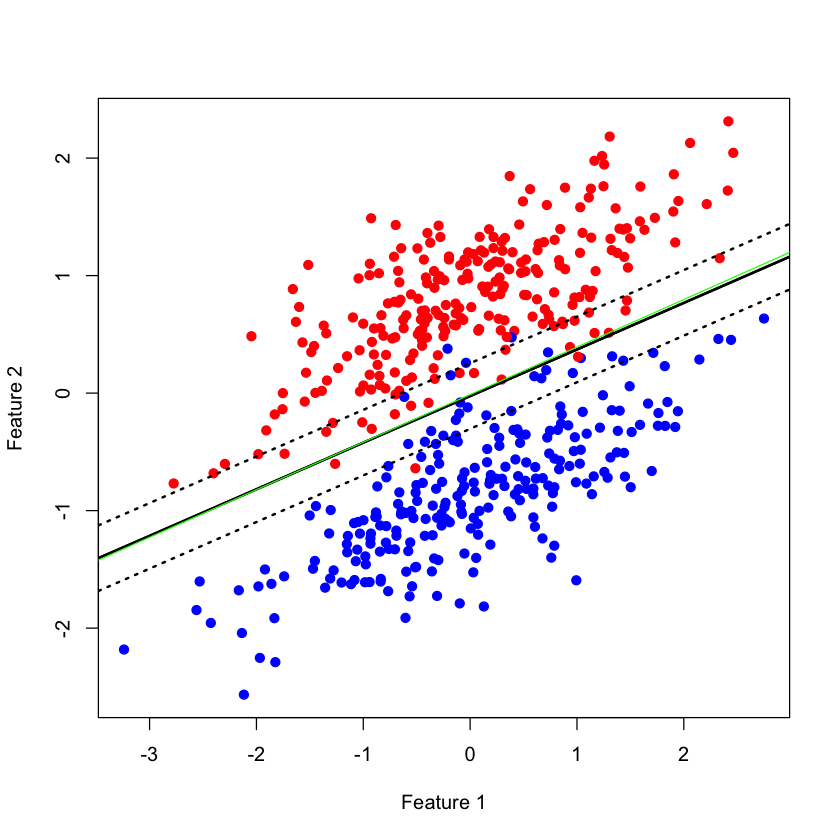

In [150]:
plot(z_matrix[, 1], z_matrix[, 2], 
     col = ifelse(z_matrix[, 3] == 1, "red", "blue"), 
     pch = 19, xlab = "Feature 1", ylab = "Feature 2")

intercept_mine <- -b_opt / w_opt[2]
slope_mine <- -w_opt[1] / w_opt[2]

margin_plus_intercept <- intercept_mine + (1 / w_opt[2])
margin_minus_intercept <- intercept_mine - (1 / w_opt[2])

abline(a = intercept_mine, b = slope_mine, lwd = 2, col = "black")

abline(a = margin_plus_intercept, b = slope_mine, lwd = 2, lty = 3)
abline(a = margin_minus_intercept, b = slope_mine, lwd = 2, lty = 3)

abline(a = intercept_mine, b = slope_mine, lwd = 2, col = "black")

abline(a= intercept_bench, b=slope_bench, col="green")


The green line shows the benchmark decision boundary computed by the SVM function which closely aligns with the decision boundary I calculated (black). 
This was done with fixed $\lambda =0.01$, but can achieve better results by tuning $\lambda$.


In [151]:
library(e1071)
tuned_benchmark <- tune.svm(as.factor(y) ~ ., data = train.data.4, kernel = "linear", cost = (0.001:100))
bestC <- tuned_benchmark$best.parameters$cost
cat("Best C:", bestC)

Best C: 1.001

Two equivalent formulations just varying where constant applied: 

$$J(w) = \frac{\lambda}{2} ||w||^2+ \frac{1}{n} \sum_{i=1}^{n} \max(0, 1 - y_i h_{w,b}(x_i)) $$ 
$$J(w) = \frac{1}{2} ||w||^2+ {C} \sum_{i=1}^{n} \max(0, 1 - y_i h_{w,b}(x_i)) $$ 

Implies equivalence if $\lambda = \frac{1}{nC}$

In [152]:
best_lambda <- 1/(nrow(z_matrix)*bestC)
cat("Corresponding lambda:", best_lambda)


Corresponding lambda: 0.001998002

In [153]:
X <- z_matrix[, -ncol(z_matrix)]
y_true <- z_matrix[, ncol(z_matrix)]

scores <- as.matrix(X) %*% w_opt + b_opt
predictions <- sign(scores)

accuracy <- mean(predictions == y_true)
cat("Prediction Accuracy:", accuracy * 100, "%\n")

Prediction Accuracy: 98.2 %


# Kernel SVM

Linear SVM works well when the data is linearly separable. This is often true when the number of features is greater than the number of observations $d \gg n$. It has low computational cost and avoids overfitting in comparison to more complex kernel models. 

The polynomial kernel is used if interactions between features are used for classification. It uses all combinations up to a specified degree $d$. 
The radial basis function (RBF) kernel maps points to an infinite dimensional feature space so it works for complex boundaries, but it is susceptible to overfitting. The parameter $\gamma$ controls how far the influence of a single support vector reaches. 


* Polynomial Kernel: $$K(x_i, x_j) = (\gamma x_i^\top x_j + c)^d$$
* Radial Basis Function : $$K(x_i, x_j) = \exp(-\gamma ||x_i - x_j||^2)$$

integer(0)

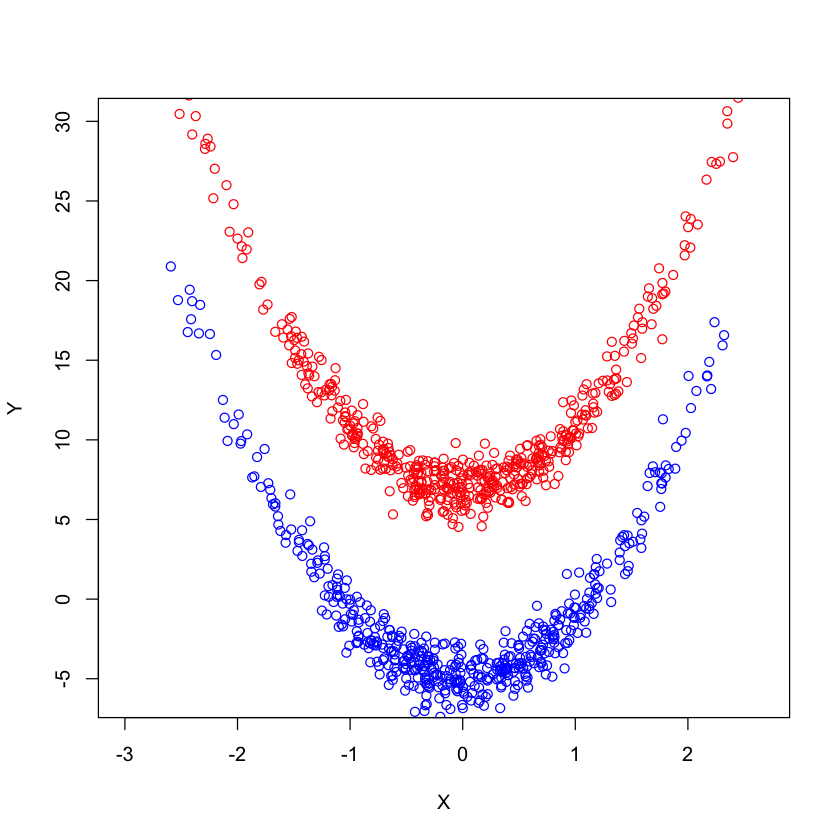

In [193]:
#Generate polynomial data
set.seed(1)
N = 1000
xx = rnorm(N)
yy = 4 * xx^2 + 1 + rnorm(N)
class = sample(N, N/2)
yy[class] = yy[class] + 6
yy[-class] = yy[-class] - 6
x <- cbind(xx,yy)
plot(x[class,1], x[class,2], col = "red", xlab = "X", ylab = "Y", ylim = c(-6, 30)) +
  points(x[-class,1], x[-class,2], col = "blue")




In [194]:
# vector of true -1, 1 labels 
y = rep(-1, N)
y[class] = 1
data = data.frame(x, y = as.factor(y))
#train svm with polynomial kernel degree 2 
train = sample(N, N/2)
data_train = data[train, ]
data_eval = data[-train, ]

#cross val to train
set.seed(1)
tune.out <- tune(svm, y ~ ., data = data_train, 
                 kernel = "polynomial", 
                 ranges = list(
                   cost = c(0.01, 0.05, 0.1),
                   gamma = c(0.5,1,2.0),
                   coef0 = c(0,1,2),
                   degree = c(1,2,3)
                 )
)
summary(tune.out)



Parameter tuning of 'svm':

- sampling method: 10-fold cross validation 

- best parameters:
 cost gamma coef0 degree
 0.05   0.5     1      2

- best performance: 0 

- Detailed performance results:
   cost gamma coef0 degree error dispersion
1  0.01   0.5     0      1 0.072 0.03425395
2  0.05   0.5     0      1 0.080 0.04000000
3  0.10   0.5     0      1 0.078 0.03705851
4  0.01   1.0     0      1 0.074 0.03657564
5  0.05   1.0     0      1 0.078 0.03705851
6  0.10   1.0     0      1 0.074 0.03657564
7  0.01   2.0     0      1 0.080 0.04000000
8  0.05   2.0     0      1 0.074 0.03657564
9  0.10   2.0     0      1 0.072 0.03425395
10 0.01   0.5     1      1 0.072 0.03425395
11 0.05   0.5     1      1 0.080 0.04000000
12 0.10   0.5     1      1 0.078 0.03705851
13 0.01   1.0     1      1 0.074 0.03657564
14 0.05   1.0     1      1 0.078 0.03705851
15 0.10   1.0     1      1 0.074 0.03657564
16 0.01   2.0     1      1 0.080 0.04000000
17 0.05   2.0     1      1 0.074 0.03657564
18 0.10

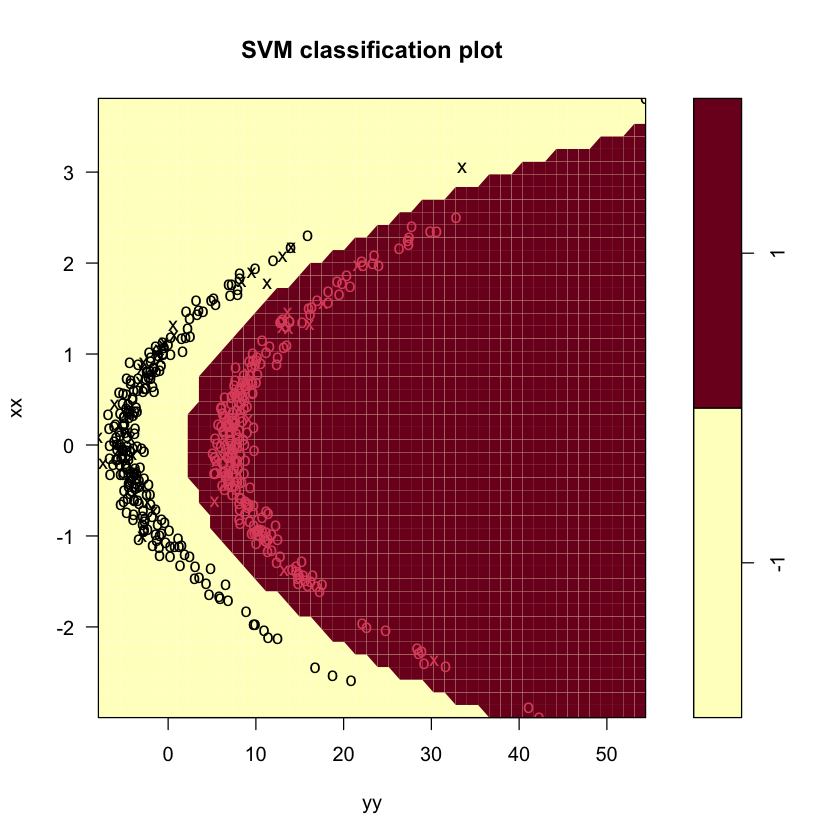

In [196]:
#model using tuned params
svmfit <- svm(y ~ ., 
              data = data_train, 
              kernel = "polynomial",  
              degree = 2, 
              gamma = 0.5,
              coef0 = 1,
              cost = 0.05, 
              scale = FALSE)

plot(svmfit, data_eval)


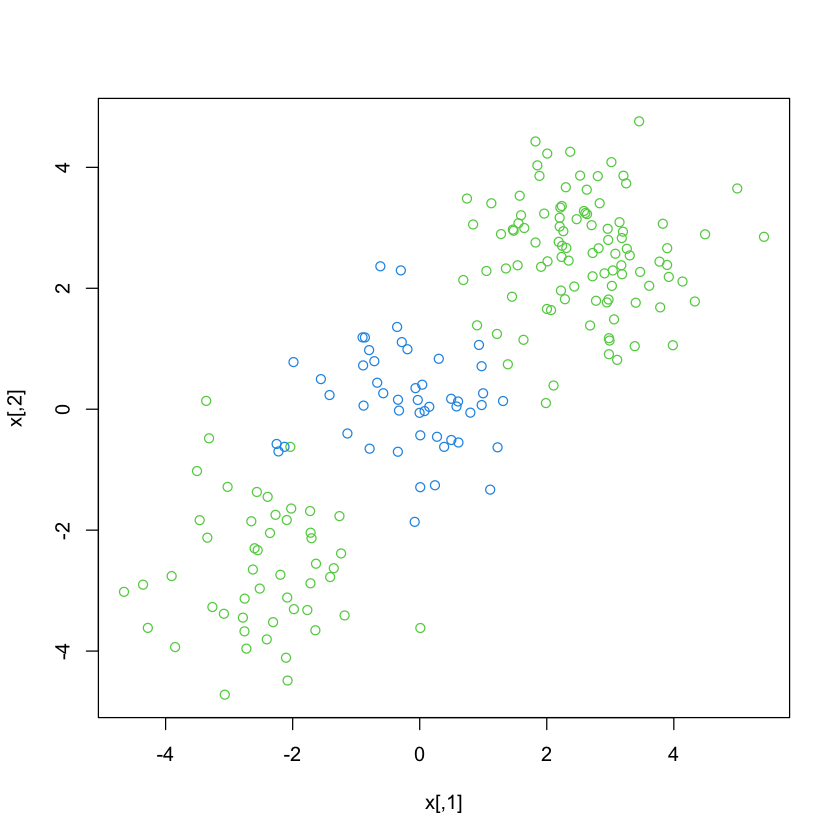

In [204]:
##SVM with radial kernel
n <- 200
x <- matrix(rnorm(n*2), ncol = 2)
x[1:100,] <- x[1:100,] + 2.5
x[101:150,] <- x[101:150,] - 2.5
y <- c(rep(1,150), rep(2,50))
data <- data.frame(x,y=as.factor(y))
plot(x, col = y+2)

In [207]:
train = sample(n, n/2)
data_train = data[train, ]
data_eval = data[-train, ]

tune.out <- tune(svm, factor(y) ~ ., data = data_train, 
                 kernel = "radial", 
                 ranges = list(
                   cost = c(0.01, 0.05, 0.1),
                   gamma = c(0.5,1,2.0)
                 )
)
summary(tune.out)


Parameter tuning of 'svm':

- sampling method: 10-fold cross validation 

- best parameters:
 cost gamma
  0.1     1

- best performance: 0.07 

- Detailed performance results:
  cost gamma error dispersion
1 0.01   0.5  0.28  0.1686548
2 0.05   0.5  0.28  0.1686548
3 0.10   0.5  0.15  0.1900292
4 0.01   1.0  0.28  0.1686548
5 0.05   1.0  0.28  0.1686548
6 0.10   1.0  0.07  0.1251666
7 0.01   2.0  0.28  0.1686548
8 0.05   2.0  0.28  0.1686548
9 0.10   2.0  0.07  0.1251666


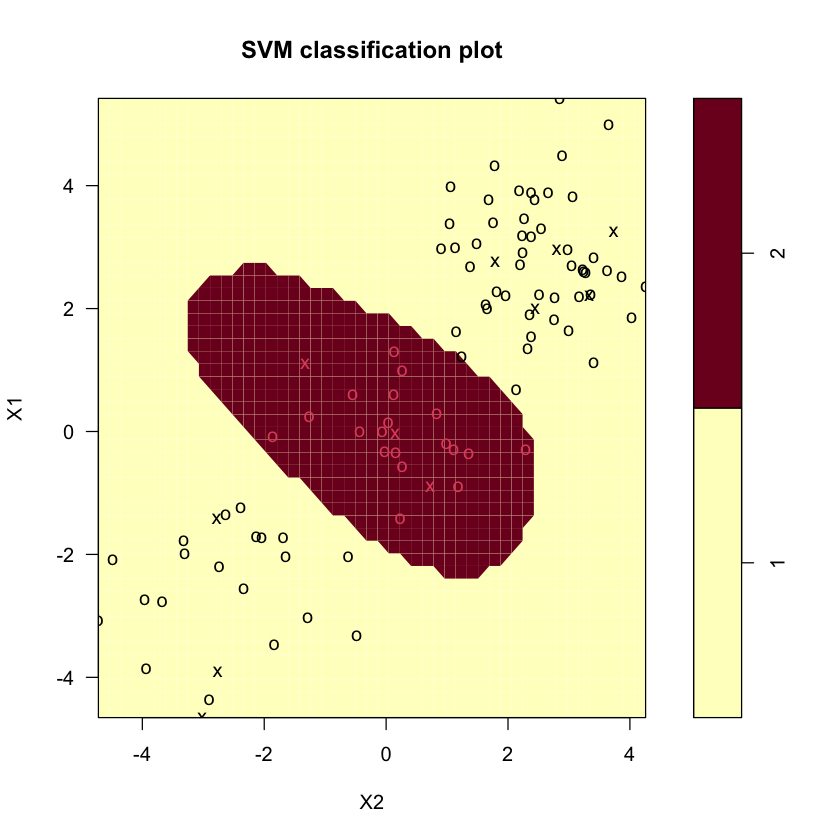

In [210]:
svmfit <- svm( factor(y) ~ ., 
               data = dat, 
               scale = FALSE, 
               kernel = "radial", 
               gamma = 0.1,
               cost = 1)

plot(svmfit, data_eval)
